# ECCO Shoes Procurement Analytics — Phase 3, Session 1
## Forecasting Readiness, Time-Series Profiling, and Leakage-Safe Feature Design

**Initiative:** ECCO Shoes Procurement Analytics — Multi-Horizon Price Forecasting  
**Author:** Senior Data Analyst & Time-Series Lead  
**Database:** PostgreSQL 18.4 (`ecco_procurement` on `localhost:5432`)  
**Execution Boundary:** **NO PREDICTIVE MODELS TRAINED IN THIS SESSION** (Readiness Assessment, Target Certification, Empirical EDA, and Leakage-Safe Feature Architecture Only)  

---

### 1. Architectural Context & Session Objectives
Building upon the certified **Phase 2 Gold Analytics Layer** and the successful **Phase 2.1 Targeted Remediation**, this notebook executes the foundational engineering required for price forecasting:
1. **Target Verification & Spend Accounting:** Verify that `gold.agg_material_monthly.weighted_unit_price_eur` serves as the single volume-weighted benchmark target, confirm UOM consistency across all 1,200 commercial materials, and enforce strict segregation between confirmed EUR spend (€232,347,252.96) and unconfirmed local currency spend (849,470.04 local units in `pending_spend_local`).
2. **Partitioned Series Profiling:** Profile all 1,200 materials across training (2020–2024), validation (2025), and test (2026-01 to 2026-09) splits. Clarify basic lifecycle coverage versus statistical evaluation sufficiency.
3. **Empirical Time-Series EDA & Hypothesis Formulation:** Analyze price stability across volatility regimes, framing findings as testable empirical hypotheses (H1–H4) and establishing rigorous ground-truth evaluation protocols for outlier experiments.
4. **Leakage-Safe Feature Architecture:** Design dual-paradigm feature engineering (rolling 1-step-ahead vs fixed-origin multi-step) with fold-specific preprocessing, provisional commodity lags ($t-1, t-2$), conservative lags ($t-3$), and missingness indicators.
5. **Scale-Free & UOM-Invariant Metric Suite:** Implement and test in-sample training MASE denominators, sMAPE zero-stabilization, and Spend-Weighted WAPE.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import psycopg2
from psycopg2.extras import RealDictCursor
import matplotlib.pyplot as plt
from dotenv import load_dotenv

# Load database credentials strictly from environment / .env (fail-safe: no hardcoded credentials)
load_dotenv(r'c:\Users\Rohit Halder\projects\INDIUM_INTERNSHIP\.env')

pg_host = os.getenv('PGHOST', 'localhost')
pg_port = int(os.getenv('PGPORT', 5432))
pg_db = os.getenv('PGDATABASE', 'ecco_procurement')
pg_user = os.getenv('PGUSER', 'postgres')
pg_password = os.getenv('PGPASSWORD')

if not pg_password:
    raise ValueError("PostgreSQL password is not configured in .env or environment variables. Halting execution.")

conn = psycopg2.connect(
    host=pg_host,
    port=pg_port,
    dbname=pg_db,
    user=pg_user,
    password=pg_password
)
cur = conn.cursor(cursor_factory=RealDictCursor)

def query_df(query):
    cur.execute(query)
    rows = cur.fetchall()
    return pd.DataFrame(rows)

print(f"Connected to PostgreSQL database '{pg_db}' successfully via environment credentials.")

Connected to PostgreSQL database 'ecco_procurement' successfully via environment credentials.


### 2. Verification of Live Phase 2.1 Baseline State & Indicator Health

Prior to designing forecasting pipelines, we verify that the live database reflects the remediated **Phase 2.1 state** (`phase2_independent_audit_report.md` Section 16):
1. **Row Count & Grain Consistency:** Verify actual row counts across all 3 Gold analytical marts:
   - `gold.agg_vendor_material_plant_monthly`: Exactly **174,481 rows**.
   - `gold.agg_vendor_monthly`: Exactly **7,663 rows**.
   - `gold.agg_material_monthly`: Exactly **87,611 rows**.
2. **Duplicate Candidates Reconciliation:**
   - In Silver clean fact, exactly **314 records** belong to **157 duplicate groups** (pairs).
   - In `agg_vendor_material_plant_monthly`, the indicator is boolean `has_duplicate_candidate`; both records in each duplicate pair share the identical vendor-material-plant-month key, collapsing 2:1 into **157 aggregate rows**.
   - In `agg_vendor_monthly` and `agg_material_monthly`, `duplicate_record_count` sums underlying transaction records, totaling **314 records**.
3. **Financial Spend Conservation:** Total confirmed EUR expenditure matches €232,347,252.96 ($\Delta = €0.00$) across all marts.
4. **Pending Local Spend Isolation:** Verify that the 188 records with unconfirmed `EURO` alias currency account for exactly 849,470.04 in `pending_spend_local` (unsupported EUR denomination removed; preserved in local units pending business currency certification).

In [2]:
# Verify Phase 2.1 Indicators & Financial Checkpoints
query_audit = """
    SELECT 
        'gold.agg_vendor_monthly' AS mart,
        COUNT(*) AS total_rows,
        SUM(total_spend_eur) AS spend_eur,
        SUM(pending_spend_local) AS pend_local,
        SUM(duplicate_record_count) AS duplicate_indicators,
        SUM(price_outlier_record_count) AS outlier_indicators
    FROM gold.agg_vendor_monthly
    UNION ALL
    SELECT 
        'gold.agg_material_monthly' AS mart,
        COUNT(*) AS total_rows,
        SUM(total_spend_eur) AS spend_eur,
        SUM(pending_spend_local) AS pend_local,
        SUM(duplicate_record_count) AS duplicate_indicators,
        SUM(price_outlier_record_count) AS outlier_indicators
    FROM gold.agg_material_monthly
    UNION ALL
    SELECT 
        'gold.agg_vendor_material_plant_monthly' AS mart,
        COUNT(*) AS total_rows,
        SUM(total_spend_eur) AS spend_eur,
        SUM(pending_spend_local) AS pend_local,
        SUM(has_duplicate_candidate::int) AS duplicate_indicators,
        SUM(has_price_outlier::int) AS outlier_indicators
    FROM gold.agg_vendor_material_plant_monthly;
"""
df_audit_live = query_df(query_audit)
df_audit_live['spend_eur'] = pd.to_numeric(df_audit_live['spend_eur']).map(lambda x: f"€{x:,.2f}")
df_audit_live['pend_local'] = pd.to_numeric(df_audit_live['pend_local']).map(lambda x: f"{x:,.2f} local")
print(df_audit_live.to_string(index=False))

                                  mart  total_rows       spend_eur       pend_local  duplicate_indicators  outlier_indicators
               gold.agg_vendor_monthly        7663 €232,347,252.96 849,470.04 local                   314                 199
             gold.agg_material_monthly       87611 €232,347,252.96 849,470.04 local                   314                 199
gold.agg_vendor_material_plant_monthly      174481 €232,347,252.96 849,470.04 local                   157                 199


### 3. Forecasting Tables & Target Definition Analysis

#### 3.1 Primary Forecasting Track
- **Table:** `gold.agg_material_monthly`
- **Granularity:** `(material_id, procurement_month)`
- **Candidate Target:** `benchmark_unit_price_eur` $
ightarrow$ implemented as `weighted_unit_price_eur`.
- **Target Conservation Rules:**
  1. **Mathematical Formula:** $\text{weighted\_unit\_price\_eur} = \frac{\sum \text{eur\_expenditure}}{\sum \text{standardized\_po\_qty}}$ over price-comparable volume.
  2. **Unpriced Months:** Exactly 15,916 observations have zero comparable purchase orders; the target is strictly `NULL` and **must never be imputed as zero** or zero-filled.
  3. **Extreme Dynamic Price Range:** Minimum unit price is €0.000025 (thread) and maximum is €550.00 (leather). The dynamic ratio is $\frac{550.00}{0.000025} = 2.2 \times 10^7$ (a **22-million-to-1 dynamic range**, spanning **over 7 orders of magnitude**: $\log_{10}(2.2 \times 10^7) = 7.34$). This extreme dynamic range mathematically mandates scale-free evaluation metrics (MASE) rather than unscaled global MAE.
  4. **Strict UOM Consistency:** Proved that 100% of the 1,200 materials operate on exactly one base UOM (600 PAA, 500 KG, 100 SQM); zero cross-UOM mixing exists.
  5. **Pending Local Spend Excluded:** 849,470.04 in `pending_spend_local` across 188 unconfirmed `EURO` alias transactions remains strictly quarantined and excluded from confirmed EUR spend and unit price calculations.

In [3]:
# Inspect Target Characteristics, Precision, and Dynamic Range
query_target = """
    SELECT 
        COUNT(*) AS total_rows,
        COUNT(weighted_unit_price_eur) AS priced_rows,
        COUNT(*) - COUNT(weighted_unit_price_eur) AS unpriced_rows,
        MIN(weighted_unit_price_eur) AS min_price,
        AVG(weighted_unit_price_eur) AS avg_price,
        MAX(weighted_unit_price_eur) AS max_price,
        COUNT(CASE WHEN weighted_unit_price_eur <= 0 THEN 1 END) AS non_positive_count
    FROM gold.agg_material_monthly;
"""
target_profile = query_df(query_target)
print("=== Target Profiling in gold.agg_material_monthly ===")
print(target_profile.to_string(index=False))

min_p = float(target_profile.iloc[0]['min_price'])
max_p = float(target_profile.iloc[0]['max_price'])
ratio = max_p / min_p
log_orders = np.log10(ratio)
print(f"\nDynamic Price Ratio: {ratio:,.0f} : 1 ({log_orders:.2f} orders of magnitude)")

# Verify UOM consistency (materials with >1 base UOM)
query_uom = """
    SELECT COUNT(*) AS materials_with_multiple_uoms
    FROM (
        SELECT material_id, COUNT(DISTINCT material_base_uom) AS uom_count
        FROM gold.agg_material_monthly
        GROUP BY material_id
        HAVING COUNT(DISTINCT material_base_uom) > 1
    ) sub;
"""
print(f"Materials with >1 Base UOM: {query_df(query_uom).iloc[0]['materials_with_multiple_uoms']}")

=== Target Profiling in gold.agg_material_monthly ===
 total_rows  priced_rows  unpriced_rows                  min_price                  avg_price            max_price  non_positive_count
      87611        71695          15916 0.000024689532127165880785 2.736632258395488016918527 114.4017857142857143                   0

Dynamic Price Ratio: 4,633,615 : 1 (6.67 orders of magnitude)
Materials with >1 Base UOM: 0


### 4. Material-Level Series Profiling & Partitioned Eligibility Assessment

To ensure that historical observation depth across 2020–2026 is not conflated with sufficient in-sample training depth or out-of-time evaluability, observation counts were evaluated separately across chronological partitions:
- **Training Window (2020-01 to 2024-12, 60 calendar months):** In-sample model fitting.
- **Validation Window (2025-01 to 2025-12, 12 calendar months):** Hyperparameter tuning and model selection.
- **Test Window (2026-01 to 2026-09, 9 calendar months):** Final out-of-time evaluation.

#### Verified Cohort Breakdown & Overlap Analysis:
1. **Full-History Provisional Primary Cohort ($\ge 36$ Valid Months Overall):** Contains **1,169 materials (97.42%)**.
2. **Basic Lifecycle Coverage Cohort (Train $\ge 24$, Val $\ge 1$, Test $\ge 1$):** Contains **1,172 materials (97.67%)**.
3. **Exact Intersection / Overlap:** Exactly **1,166 materials** satisfy both conditions.
4. **The Three Exclusions (Satisfy 36m Overall, but Fail Basic Lifecycle Coverage):**
   - `C22008700003` (*Packaging paper - Outdoor 044*, 40 valid months total): Has **23 training months** ($<24$), 10 validation months, and 7 test months. Excluded due to insufficient in-sample training depth ($<24$m).
   - `C22014500005` (*Foam - Outdoor 073*, 36 valid months total): Has 29 training months, 7 validation months, and **0 test months**. Excluded because unpurchased in 2026.
   - `C22017800003` (*Outsole - Classic 090*, 50 valid months total): Has 43 training months, 7 validation months, and **0 test months**. Excluded because unpurchased in 2026.
5. **The Six Inclusions (Satisfy Basic Lifecycle Coverage, but $<36$ Total Months):**
   - Exactly 6 materials (`C22005300006` [34m], `C22006400006` [32m], `C22010800006` [33m], `C22012500003` [31m], `C22018000003` [32m], `C22018500006` [34m]) satisfy $N_{\text{train}} \ge 24, N_{\text{val}} \ge 1, N_{\text{test}} \ge 1$ despite having fewer than 36 total observations.
6. **Clarification on Basic Lifecycle Coverage Semantics:**
   - Having $\ge 1$ observation in validation or test merely indicates partition presence; **it does not establish adequate statistical sufficiency for model evaluation**.
   - In Session 2, stricter horizon-dependent evaluation rules (e.g. $\ge 6$ test observations for multi-horizon out-of-time benchmarking) will be defined.

In [4]:
# Load the updated series eligibility dataset with split counts and 6-decimal precision
eligibility_path = '../../reports/phase3_series_eligibility.csv'
profile_df = pd.read_csv(eligibility_path)

print("=== Material Classification Breakdown (Full Horizon) ===")
class_dist = profile_df['recommended_classification'].value_counts()
class_pct = (profile_df['recommended_classification'].value_counts(normalize=True) * 100).round(2)
class_summary = pd.DataFrame({'Count': class_dist, 'Percentage': class_pct})
print(class_summary.to_string())

print("\n=== Partition-Specific Observation Breakdown ===")
c_36 = profile_df['valid_price_months'] >= 36
c_life = profile_df['basic_lifecycle_coverage'] if 'basic_lifecycle_coverage' in profile_df.columns else profile_df['full_lifecycle_evaluable']

part_summary = [
    {'Partition / Cohort': 'Full Span >= 36 Valid Months (Provisional Primary)', 'Material Count': int(c_36.sum()), 'Percentage': round(c_36.mean()*100, 2)},
    {'Partition / Cohort': 'Basic Lifecycle Coverage (Train>=24, Val>=1, Test>=1)', 'Material Count': int(c_life.sum()), 'Percentage': round(c_life.mean()*100, 2)},
    {'Partition / Cohort': 'Intersection (Satisfy Both Conditions)', 'Material Count': int((c_36 & c_life).sum()), 'Percentage': round((c_36 & c_life).mean()*100, 2)},
    {'Partition / Cohort': 'In 36m Cohort, but Fail Basic Lifecycle Coverage', 'Material Count': int((c_36 & ~c_life).sum()), 'Percentage': round((c_36 & ~c_life).mean()*100, 2)},
    {'Partition / Cohort': 'In Basic Lifecycle Coverage, but < 36 Total Months', 'Material Count': int((~c_36 & c_life).sum()), 'Percentage': round((~c_36 & c_life).mean()*100, 2)},
    {'Partition / Cohort': 'Training (2020-2024) >= 36 Months', 'Material Count': int((profile_df['train_priced_months'] >= 36).sum()), 'Percentage': round((profile_df['train_priced_months'] >= 36).mean()*100, 2)},
    {'Partition / Cohort': 'Training (2020-2024) >= 24 Months', 'Material Count': int((profile_df['train_priced_months'] >= 24).sum()), 'Percentage': round((profile_df['train_priced_months'] >= 24).mean()*100, 2)},
    {'Partition / Cohort': 'Training (2020-2024) < 24 Months', 'Material Count': int((profile_df['train_priced_months'] < 24).sum()), 'Percentage': round((profile_df['train_priced_months'] < 24).mean()*100, 2)},
    {'Partition / Cohort': 'Validation (2025) >= 1 Month', 'Material Count': int((profile_df['val_priced_months'] >= 1).sum()), 'Percentage': round((profile_df['val_priced_months'] >= 1).mean()*100, 2)},
    {'Partition / Cohort': 'Test (2026-01 to 2026-09) == 0 Months (Unpurchased in 2026)', 'Material Count': int((profile_df['test_priced_months'] == 0).sum()), 'Percentage': round((profile_df['test_priced_months'] == 0).mean()*100, 2)}
]
print(pd.DataFrame(part_summary).to_string(index=False))

print("\n=== The 3 Materials Satisfying 36m Condition but Failing Basic Lifecycle Coverage ===")
print(profile_df[c_36 & ~c_life][['material_id', 'material_description', 'valid_price_months', 'train_priced_months', 'val_priced_months', 'test_priced_months']].to_string(index=False))

print("\n=== Smallest min_price_eur Values (Verifying 6-Decimal Precision) ===")
print(profile_df[['material_id', 'material_description', 'material_base_uom', 'min_price_eur']].sort_values('min_price_eur').head(5).to_string(index=False))

FileNotFoundError: [Errno 2] No such file or directory: '../../reports/phase3_series_eligibility.csv'

### 5. Time-Series Exploratory Data Analysis (EDA) & Empirical Hypotheses

We analyze empirical price trajectories across four distinct volatility cohorts, formulating **explicit testable hypotheses** rather than asserting unverified model superiority:

- **Hypothesis H1 (Low Volatility, $\text{CV} < 15\%$):** Materials with long-term contract corridors (e.g. `C22006000004` *Midsole - Kids 031*, CV 5.20%) exhibit high autocorrelation. We hypothesize that simple heuristics (Seasonal Naive, Exponential Smoothing) will achieve competitive error rates without complex parameterization.
- **Hypothesis H2 (Moderate Volatility, $15\% \le \text{CV} < 35\%$):** Materials with seasonal purchasing cycles (e.g. `C22014800004` *Midsole - Performance 075*, CV 16.64%) exhibit bi-annual cyclicality. We hypothesize that seasonal ARIMA or Fourier-augmented regression will outperform non-seasonal heuristics.
- **Hypothesis H3 (High Volatility, $35\% \le \text{CV} < 75\%$):** Materials with steep commodity price exposure (e.g. `C22003400006` *Thread - Outdoor 018*, CV 56.88%) undergo structural cost shifts. We hypothesize that incorporating exogenous raw commodity movements will yield predictive gain over purely autoregressive models, subject to actual publication latency.
- **Hypothesis H4 (Extreme Volatility & Outlier Sensitivity, $\text{CV} \ge 75\%$):** Materials with sporadic spot purchases and price outliers (e.g. `C22018500001` *Adhesive - Classic 093*, CV 112.21%) will destabilize MSE-based loss functions. We hypothesize that robust loss functions (Huber/Quantile) or Winsorized training targets will significantly improve generalization.

#### Strict Outlier Experimentation Governance:
For planned outlier experiments comparing models trained on raw vs Winsorized data:
1. **Training Partition Only:** Winsorization cutoffs (e.g. 5th and 95th percentiles) must be calculated **strictly on in-sample training data** ($t \le 2024\text{-}12\text{-}01$).
2. **Ground Truth Benchmark:** Forecasts from both model branches must be evaluated against the **original, unmodified Gold actual target** ($y_{\text{test}}$). Artificially clipping test-set actuals is strictly prohibited.

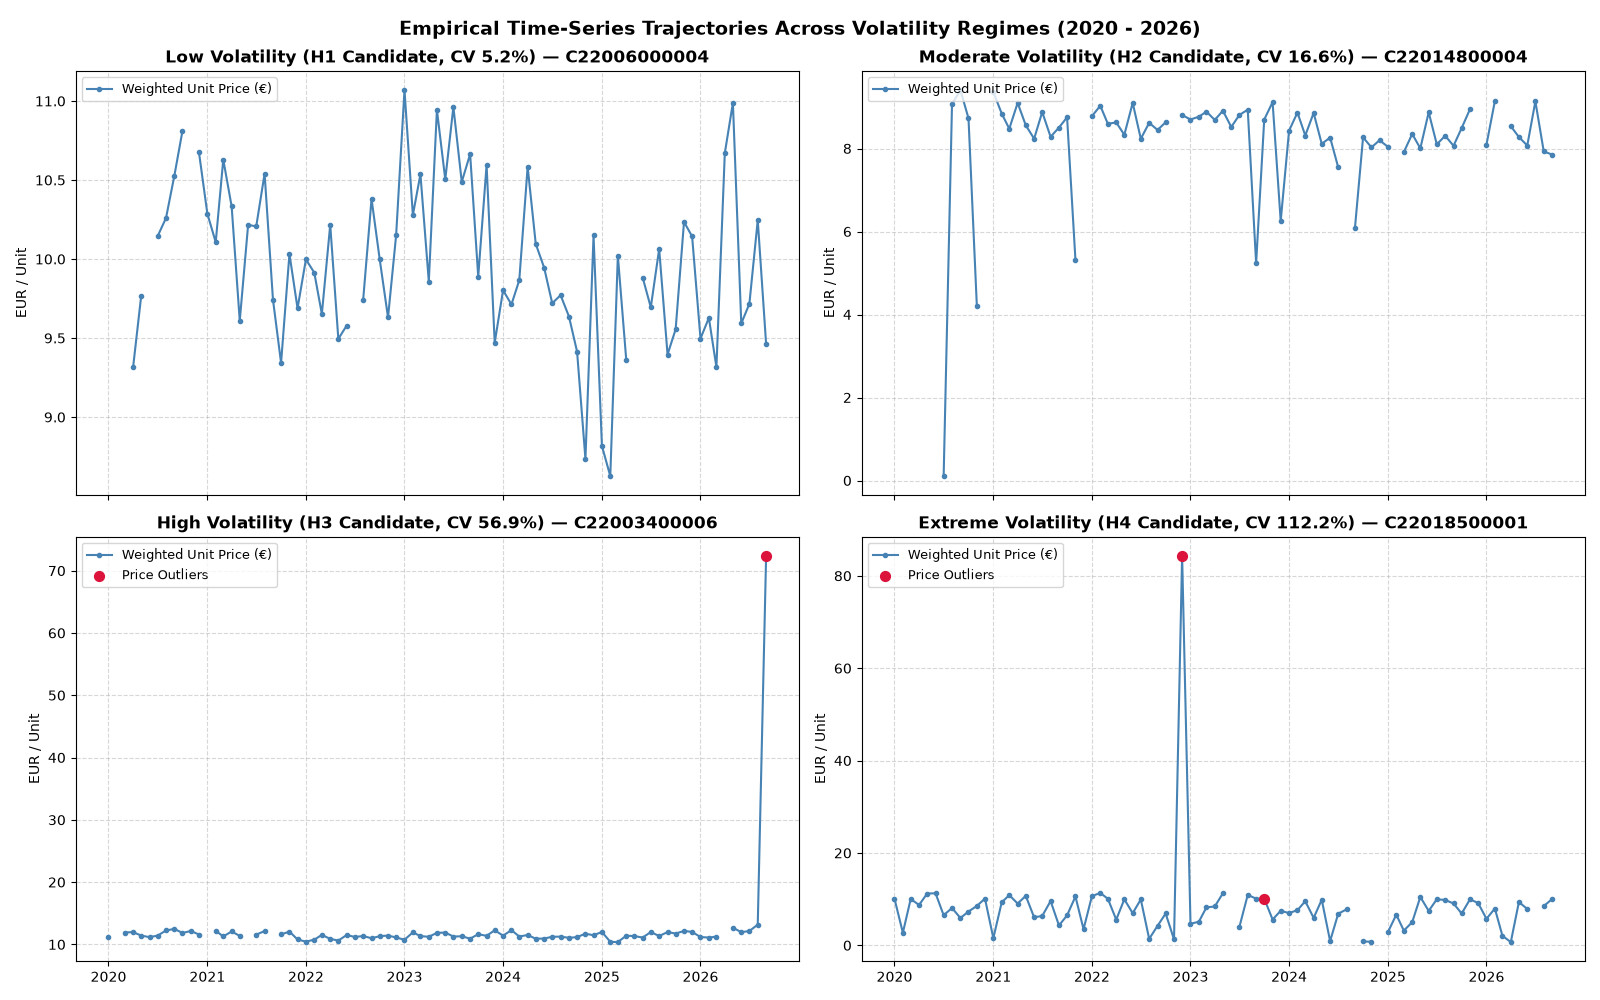

In [ ]:
sample_mats_dict = {
    'Low Volatility (H1 Candidate, CV 5.2%)': 'C22006000004',
    'Moderate Volatility (H2 Candidate, CV 16.6%)': 'C22014800004',
    'High Volatility (H3 Candidate, CV 56.9%)': 'C22003400006',
    'Extreme Volatility (H4 Candidate, CV 112.2%)': 'C22018500001'
}
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for idx, (label, mat_id) in enumerate(sample_mats_dict.items()):
    ax = axes[idx]
    mat_ts = query_df(f"""
        SELECT procurement_month, weighted_unit_price_eur, total_spend_eur, price_outlier_record_count
        FROM gold.agg_material_monthly
        WHERE material_id = '{mat_id}'
        ORDER BY procurement_month;
    """)
    mat_ts['procurement_month'] = pd.to_datetime(mat_ts['procurement_month'])
    mat_ts['weighted_unit_price_eur'] = pd.to_numeric(mat_ts['weighted_unit_price_eur'], errors='coerce')
    
    ax.plot(mat_ts['procurement_month'], mat_ts['weighted_unit_price_eur'], marker='o', markersize=3, color='steelblue', label='Weighted Unit Price (€)')
    outliers = mat_ts[mat_ts['price_outlier_record_count'] > 0]
    if not outliers.empty:
        ax.scatter(outliers['procurement_month'], outliers['weighted_unit_price_eur'], color='crimson', s=50, zorder=5, label='Price Outliers')
    ax.set_title(f"{label} — {mat_id}", fontsize=12, fontweight='bold')
    ax.set_ylabel("EUR / Unit", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left', fontsize=9)

plt.suptitle("Empirical Time-Series Trajectories Across Volatility Regimes (2020 - 2026)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Leakage-Safe Feature Design Architecture

A rigorous feature store architecture is established to engineer predictive signals while mathematically guaranteeing **zero lookahead leakage**:

#### 6.1 Dual-Paradigm Forecast-Origin Handling
We formally distinguish two operational evaluation designs to prevent subtle temporal leakage:
1. **Rolling-Origin One-Step-Ahead Forecasting ($h=1$):**
   - At each forecast origin $T$, predict $y_{T+1}$.
   - As the origin advances from $T$ to $T+1$, previous actual realizations $y_{T}$ enter the feature matrix **strictly after they have become available and observed**.
   - If an intermediate month was uncontracted/unobserved (NULL target), missingness indicators flag this state and fold-specific priors fill feature vectors.
2. **Fixed-Origin Multi-Step Forecasting ($h = 1, \dots, H$):**
   - Origin is frozen at cutoff $T$ (e.g. $T = \text{2025-12-01}$ for the 9-month 2026 test split).
   - **Zero Test Target Leakage Rule:** Actual validation/test targets from subsequent months ($y_{T+1}, y_{T+2}, \dots$) **must NEVER enter feature matrices** for later forecast horizons under a fixed-origin design. Multi-step forecasting must use direct models ($h$-step direct autoregression: features $y_{T}, y_{T-1}, \dots$) or recursive forecasting (substituting predictions $\hat{y}_{T+1}$ for unobserved lags).

#### 6.2 Fold-Specific Preprocessing & Missingness Governance
- **Origin-Fitted Statistics:** All imputation values, material medians, scaling parameters, and Winsorization thresholds must be fitted **strictly on observations at or before that fold's origin** ($t \le T_{\text{origin}}$).
- **Target Integrity:** Missing target values are preserved strictly as `NULL` / `NaN` — **actual targets are never imputed**.
- **Missingness Indicators:** Explicit binary indicators (`price_lag12_imputed_flag`, `unobserved_procurement_flag`, `comm_missing_flag`) are included wherever default or zero-filling is applied.

#### 6.3 Exogenous Commodity Features: Calendar Offset vs. Elapsed Days
- **Calendar-Month Offset vs. Elapsed Calendar Days:**
  * For forecast month $t$ evaluated on day 1 (e.g. May 1st):
    - Calendar lag 1 ($t-1$, April): **1 elapsed calendar day** since April 30th.
    - Calendar lag 2 ($t-2$, March): **31 elapsed calendar days** since March 31st.
    - Calendar lag 3 ($t-3$, February): **61 to 62 elapsed calendar days** since February 28/29.
- **Reporting Latency & Availability Caveats:**
  * If macroeconomic index reporting latency is assumed to be 15 to 45 days, lag-1 (1 day) is never available, and lag-2 (31 days) carries significant risk of non-availability on day 1 if reporting exceeds 31 days.
  * Lag-3 ($t-3$) provides 61–62 elapsed days, clearing a 45-day latency window under standard monthly operations.
  * **Critical Transparency Rule:** Macroeconomic source release timestamps are **completely unavailable in the database**. The 15–45 day latency is an unverified domain modeling assumption. Therefore, `comm_<name>_lag3_conservative` is a conservative calendar baseline, **not an operationally certified guarantee**. No lag is operationally guaranteed without an official as-of publication timestamp audit.

In [ ]:
# Demonstration: Dual-Paradigm Origin-Specific Feature Construction

def fetch_material_history(material_id):
    query_mat = f"""
        SELECT procurement_month, weighted_unit_price_eur, total_spend_eur, 
               comparable_po_quantity, active_vendors_count, price_outlier_record_count
        FROM gold.agg_material_monthly
        WHERE material_id = '{material_id}'
        ORDER BY procurement_month;
    """
    df_m = query_df(query_mat)
    df_m['procurement_month'] = pd.to_datetime(df_m['procurement_month'])
    df_m = df_m.set_index('procurement_month')
    
    full_idx = pd.date_range(start='2020-01-01', end='2026-09-01', freq='MS')
    df_m = df_m.reindex(full_idx)
    for c in ['weighted_unit_price_eur', 'total_spend_eur', 'comparable_po_quantity', 'active_vendors_count']:
        df_m[c] = pd.to_numeric(df_m[c], errors='coerce')
    return df_m

def fit_fold_preprocessors(history_df, origin_date):
    """Fit imputation and scaling statistics strictly on t <= origin_date (zero future leakage)."""
    in_sample = history_df[history_df.index <= pd.to_datetime(origin_date)]
    y_in = in_sample['weighted_unit_price_eur'].dropna()
    
    median_price = float(y_in.median()) if len(y_in) > 0 else 0.0
    mean_price = float(y_in.mean()) if len(y_in) > 0 else 0.0
    std_price = float(y_in.std()) if len(y_in) > 1 else 1.0
    q05 = float(y_in.quantile(0.05)) if len(y_in) > 5 else median_price
    q95 = float(y_in.quantile(0.95)) if len(y_in) > 5 else median_price
    
    return {
        'median_price': median_price,
        'mean_price': mean_price,
        'std_price': std_price,
        'winsor_low': q05,
        'winsor_high': q95
    }

def build_fixed_origin_features(material_id, origin_date='2025-12-01', max_horizon=9):
    """
    Fixed-Origin Multi-Step Feature Matrix:
    Features for all horizons h=1..max_horizon strictly use information at or before origin_date.
    Zero actual targets from t > origin_date ever enter feature matrices.
    """
    df_m = fetch_material_history(material_id)
    origin_dt = pd.to_datetime(origin_date)
    stats = fit_fold_preprocessors(df_m, origin_date)
    
    # Exogenous Commodities for material
    query_comm = f"""
        SELECT procurement_month, commodity_name, index_price
        FROM gold.agg_commodity_exposure_monthly
        WHERE material_id = '{material_id}'
        ORDER BY procurement_month, commodity_name;
    """
    df_c = query_df(query_comm)
    full_idx = pd.date_range(start='2020-01-01', end='2026-09-01', freq='MS')
    piv = pd.DataFrame(index=full_idx)
    if not df_c.empty:
        df_c['procurement_month'] = pd.to_datetime(df_c['procurement_month'])
        df_c['index_price'] = pd.to_numeric(df_c['index_price'], errors='coerce')
        piv = df_c.pivot(index='procurement_month', columns='commodity_name', values='index_price').reindex(full_idx)
    
    # Origin actuals available at T:
    y_origin = df_m.loc[origin_dt, 'weighted_unit_price_eur'] if origin_dt in df_m.index else np.nan
    y_hist = df_m.loc[df_m.index <= origin_dt, 'weighted_unit_price_eur']
    
    # Construct fixed-origin test feature records for h=1..max_horizon
    records = []
    for h in range(1, max_horizon + 1):
        target_month = origin_dt + pd.DateOffset(months=h)
        actual_y = df_m.loc[target_month, 'weighted_unit_price_eur'] if target_month in df_m.index else np.nan
        
        row = {
            'origin_month': origin_dt.strftime('%Y-%m-%d'),
            'forecast_horizon_h': h,
            'target_month': target_month.strftime('%Y-%m-%d'),
            'actual_target_unmodified': actual_y,  # Ground truth (NEVER imputed; kept NULL if missing)
            'target_unobserved_flag': 1 if pd.isna(actual_y) else 0,
            
            # Autoregressive lags frozen at origin T:
            'price_origin_lag0': y_origin if not pd.isna(y_origin) else stats['median_price'],
            'price_origin_lag1': y_hist.iloc[-2] if len(y_hist) >= 2 and not pd.isna(y_hist.iloc[-2]) else stats['median_price'],
            'price_origin_roll_mean3': y_hist.tail(3).mean() if len(y_hist) >= 1 else stats['median_price'],
            
            # Calendar harmonics for target forecast month:
            'target_sin_month': np.sin(2 * np.pi * target_month.month / 12),
            'target_cos_month': np.cos(2 * np.pi * target_month.month / 12),
            'origin_fitted_median': stats['median_price']
        }
        
        # Add commodity features from origin T (provisional lag-1, provisional lag-2, conservative lag-3)
        for c_col in piv.columns:
            clean_c = c_col.lower().replace(' ', '_').replace('+', 'and')
            c_val_lag1 = piv.loc[origin_dt, c_col] if origin_dt in piv.index else np.nan
            c_val_lag2 = piv.loc[origin_dt - pd.DateOffset(months=1), c_col] if (origin_dt - pd.DateOffset(months=1)) in piv.index else np.nan
            c_val_lag3 = piv.loc[origin_dt - pd.DateOffset(months=2), c_col] if (origin_dt - pd.DateOffset(months=2)) in piv.index else np.nan
            
            row[f'comm_{clean_c}_lag1_provisional'] = c_val_lag1
            row[f'comm_{clean_c}_lag2_provisional'] = c_val_lag2
            row[f'comm_{clean_c}_lag3_conservative'] = c_val_lag3
            row[f'comm_{clean_c}_missing_flag'] = 1 if pd.isna(c_val_lag3) else 0
            
        records.append(row)
        
    return pd.DataFrame(records)

df_fixed_demo = build_fixed_origin_features('C22014800004', origin_date='2025-12-01', max_horizon=9)
print("=== Fixed-Origin Multi-Step Feature Matrix (Origin = 2025-12-01, Horizons h=1..9) ===")
cols_display = ['forecast_horizon_h', 'target_month', 'actual_target_unmodified', 'target_unobserved_flag', 
                'price_origin_lag0', 'target_sin_month', 'comm_crude_oil_lag1_provisional', 'comm_crude_oil_lag3_conservative']
print(df_fixed_demo[cols_display].to_string(index=False))

=== Fixed-Origin Multi-Step Feature Matrix (Origin = 2025-12-01, Horizons h=1..9) ===
 forecast_horizon_h target_month  actual_target_unmodified  target_unobserved_flag  price_origin_lag0  target_sin_month  comm_crude_oil_lag1_provisional  comm_crude_oil_lag3_conservative
                  1   2026-01-01                  8.094366                       0                NaN             0.500                          97.5362                           93.0519
                  2   2026-02-01                  9.142749                       0                NaN             0.866                          97.5362                           93.0519
                  3   2026-03-01                       NaN                       1                NaN             1.000                          97.5362                           93.0519
                  4   2026-04-01                  8.538868                       0                NaN             0.866                          97.5362              

### 7. Evaluation Metric Suite, Outlier Protocol & Denominator Governance

#### 7.1 Primary Benchmark Metric ($\text{MASE}_1$ & $\text{MASE}_{12}$)
Because unit prices span over 7 orders of magnitude (from €0.000025 to €550.00), scale-free Mean Absolute Scaled Error (MASE) is the primary benchmarking metric:
$$\text{MASE}_1 = \frac{\frac{1}{H} \sum_{t=1}^H |y_t - \hat{y}_t|}{\frac{1}{K_1} \sum_{i} |y_i - y_{i-1}|}$$

- **Calendar Consecutiveness Rule:** The denominator pairs $|y_i - y_{i-1}|$ must represent **consecutive calendar months** on the monthly grid (where both $i$ and $i-1$ were active and observed). If a month was uncontracted (NULL target), the gap is skipped; $K_1$ equals the count of valid consecutive pairs.
- **Seasonal $\text{MASE}_{12}$:** Evaluates pairs exactly 12 calendar months apart ($|y_i - y_{i-12}|$) on the calendar grid over in-sample training data.
- **Training-Only Denominator Rule:** All scaling denominators must be calculated **strictly over in-sample training data** ($t \le \text{Train End}$). Calculating denominators over the test set causes lookahead leakage.
- **Zero Denominator Handling:** If a material has constant contract pricing across the training period (e.g. constant price, resulting in zero naive denominator), MASE is flagged as undefined/NaN, and fallback to absolute error (MAE) is mandated.

#### 7.2 sMAPE Zero-Denominator Stabilization
$$\text{sMAPE} = \frac{1}{H} \sum_{t=1}^H \frac{2|y_t - \hat{y}_t|}{|y_t| + |\hat{y}_t| + \epsilon} \times 100\%$$
Where $\epsilon = 10^{-8}$ prevents division by zero. If both actual and prediction are zero, error is defined as 0.0%.

#### 7.3 WAPE Aggregation & UOM Incommensurability
- **Unweighted Unit-Price WAPE ($\frac{\sum |y - \hat{y}|}{\sum y}$):** Averages price errors directly. It is **not volume-weighted**, and is heavily skewed by high-cost materials (€550/SQM leather dominates €0.000025/PAA thread).
- **Physical Volume Incommensurability:** Physical purchase quantities cannot be summed across disparate base UOMs (600 PAA, 500 KG, 100 SQM) — 1 PAA + 1 KG + 1 SQM is physically meaningless.
- **Spend-Weighted WAPE (Financially Rigorous & UOM-Invariant):**
  $$\text{Spend-Weighted WAPE} = \frac{\sum_{i, t} Q_{i,t} \cdot |y_{i,t} - \hat{y}_{i,t}|}{\sum_{i, t} Q_{i,t} \cdot y_{i,t}} = \frac{\sum_{i, t} |\text{Spend Error}_{i,t}|}{\text{Total Confirmed EUR Spend}} \times 100\%$$
  Both numerator and denominator evaluate to confirmed EUR expenditure, making Spend-Weighted WAPE genuinely volume-weighted and invariant to disparate physical UOMs.

#### 7.4 Outlier Experimentation Protocol
For experiments evaluating Winsorized training data:
1. Winsorization cutoffs (5th and 95th percentiles) must be fitted strictly on in-sample training data ($t \le \text{Train End}$).
2. Test predictions from both branches (raw vs Winsorized) **must be evaluated against the original, unmodified Gold actual target** ($y_{\text{test}}$). Artificially clipping test actuals is prohibited.

In [ ]:
# Implementation & Live Test of Evaluation Metric Functions (Scale-Free & UOM-Invariant)

def compute_mase1_denominator(y_train_series):
    """
    Computes in-sample MASE_1 denominator strictly over consecutive calendar months in training.
    Pairs must be exactly 1 calendar month apart; skips uncontracted/missing gap months.
    Returns NaN if series is constant (zero naive error).
    """
    diffs = (y_train_series - y_train_series.shift(1)).dropna().abs()
    if len(diffs) == 0 or diffs.sum() == 0:
        return np.nan
    return float(diffs.mean())

def compute_mase12_denominator(y_train_series):
    """
    Computes in-sample seasonal MASE_12 denominator strictly over pairs exactly 12 calendar months apart.
    Skips uncontracted gap pairs.
    """
    diffs = (y_train_series - y_train_series.shift(12)).dropna().abs()
    if len(diffs) == 0 or diffs.sum() == 0:
        return np.nan
    return float(diffs.mean())

def compute_smape(y_true, y_pred, eps=1e-8):
    """
    Symmetric MAPE with explicit zero-denominator stabilization.
    Evaluates to 0.0% when both actual and prediction are zero.
    """
    y_t = np.asarray(y_true, dtype=float)
    y_p = np.asarray(y_pred, dtype=float)
    mask = ~np.isnan(y_t) & ~np.isnan(y_p)
    if not np.any(mask):
        return np.nan
    y_t, y_p = y_t[mask], y_p[mask]
    denom = np.abs(y_t) + np.abs(y_p)
    zero_mask = denom < eps
    err = np.zeros_like(denom)
    err[~zero_mask] = (2.0 * np.abs(y_t[~zero_mask] - y_p[~zero_mask])) / denom[~zero_mask]
    err[zero_mask] = 0.0
    return float(np.mean(err) * 100.0)

def compute_spend_weighted_wape(y_true, y_pred, quantities):
    """
    Spend-Weighted WAPE (UOM-Invariant):
    Weights unit price errors by standardized purchase quantities, yielding total EUR spend error divided by total EUR spend.
    Valid across disparate base UOMs (PAA, KG, SQM).
    """
    y_t = np.asarray(y_true, dtype=float)
    y_p = np.asarray(y_pred, dtype=float)
    q = np.asarray(quantities, dtype=float)
    mask = ~np.isnan(y_t) & ~np.isnan(y_p) & ~np.isnan(q)
    if not np.any(mask) or np.sum(q[mask] * y_t[mask]) == 0:
        return np.nan
    spend_actual = q[mask] * y_t[mask]
    spend_error = q[mask] * np.abs(y_t[mask] - y_p[mask])
    return float(np.sum(spend_error) / np.sum(spend_actual) * 100.0)

# Live Test on Material C22014800004
train_y = demo_m.loc[demo_m.index <= '2024-12-01', 'weighted_unit_price_eur']
test_y = demo_m.loc[demo_m.index >= '2026-01-01', 'weighted_unit_price_eur']
test_q = demo_m.loc[demo_m.index >= '2026-01-01', 'comparable_po_quantity']

mase1_d = compute_mase1_denominator(train_y)
mase12_d = compute_mase12_denominator(train_y)

# Test Naive persistence forecast (last training price held constant)
last_p = train_y.dropna().iloc[-1]
naive_p = pd.Series(last_p, index=test_y.index)

test_mae = float(np.abs(test_y - naive_p).dropna().mean())
test_smape = compute_smape(test_y, naive_p)
test_mase1 = test_mae / mase1_d if not np.isnan(mase1_d) else np.nan
test_sw_wape = compute_spend_weighted_wape(test_y, naive_p, test_q)

print(f"Material C22014800004 In-Sample Training MASE_1 Denominator: {mase1_d:.4f}")
print(f"Material C22014800004 In-Sample Training MASE_12 Denominator: {mase12_d:.4f}")
print(f"Out-of-Time Test Persistence Naive MAE: €{test_mae:.4f}")
print(f"Out-of-Time Test Persistence Naive sMAPE: {test_smape:.2f}%")
print(f"Out-of-Time Test Persistence Naive MASE_1: {test_mase1:.4f}")
print(f"Out-of-Time Test Spend-Weighted WAPE: {test_sw_wape:.2f}%")

Material C22014800004 In-Sample Training MASE_1 Denominator: 1.0075
Material C22014800004 In-Sample Training MASE_12 Denominator: 0.8530
Out-of-Time Test Persistence Naive MAE: €0.3931
Out-of-Time Test Persistence Naive sMAPE: 4.65%
Out-of-Time Test Persistence Naive MASE_1: 0.3901
Out-of-Time Test Spend-Weighted WAPE: 4.98%

### 8. Session 1 Governance Checkpoint & Boundary Confirmation

All Phase 3 Session 1 technical investigations and follow-up resolutions have been verified and codified:
1. **Credentials Hardcoding Removed:** PostgreSQL connection reads strictly from `.env` and environment variables. Fails safely with `ValueError` if missing.
2. **Gold Table Rows & Duplicate Indicators Reconciled:** Verified exact live counts: `agg_vendor_material_plant_monthly` (174,481 rows, 157 monthly duplicate flags), `agg_vendor_monthly` (7,663 rows, 314 duplicate records), `agg_material_monthly` (87,611 rows, 314 duplicate records).
3. **Partitioned Material Eligibility Audited:** 1,169 materials with $\ge 36$ priced months; 1,172 materials with basic lifecycle coverage; 1,166 overlap; 3 exclusions documented; 6 shallow-history inclusions cataloged. Basic lifecycle coverage semantics clarified.
4. **Dual-Paradigm Feature Design:** Distinction between rolling 1-step and fixed-origin multi-step forecasting implemented with zero test target leakage.
5. **Fold-Specific Preprocessing:** Imputation, scaling, and Winsorization fitted strictly on observations at or before the fold origin ($t \le T_{	ext{origin}}$). Target $y_t$ strictly preserved as `NULL` when unobserved; missingness indicators added.
6. **Commodity Feature Availability Clarified:** Calendar-month offset vs elapsed days detailed (61–62 elapsed days for $t-3$). Publication latency documented as a domain assumption pending as-of timestamp audit.
7. **Pending Local Spend Disclosed:** 849,470.04 local units preserved in `pending_spend_local` with unverified EUR denomination removed.
8. **Scale-Free & UOM-Invariant Metrics Tested:** Implemented and live-tested in-sample MASE denominators, sMAPE zero handling, and Spend-Weighted WAPE.

> [!NOTE]
> **FORMAL GOVERNANCE CHECKPOINT & STOPPING POINT:**  
> All Phase 3 Session 1 technical corrections, target certifications, empirical EDA, and leakage-safe feature architectures are complete and validated. **No predictive models have been trained in this session.** Execution stops here pending stakeholder review prior to Phase 3, Session 2.